# Compara Bond, Rittinger y Kick en una reducción

Nivel: 3. Requisitos previos: Niveles 1 y 2 de este tema. Tiempo de lectura: 24 minutos.

## Objetivos

Compara tres hipótesis de conminución en el mismo rango de alimentación y producto, identifica el punto de calibración donde coinciden y establece qué permite y qué no permite concluir la comparación.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Configura las importaciones y registra versiones. Este paso hace reproducible la ejecución del método.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path('../../../').resolve()
sys.path.insert(0, str(repo / 'data-pipeline'))
for package in ('numpy', 'scipy', 'pandas', 'matplotlib', 'nbclient', 'nbformat', 'ipykernel'):
    print(package, importlib.metadata.version(package))

numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores del proyecto OreFlow; caso nominal de pórfido blando e índice de trabajo en `data/derived/cases/copper_porphyry_soft.json` (licencia MIT del proyecto). Las ecuaciones y supuestos comparativos están en `docs/methodologies/09_energy.md`. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

Bond: $W=W_i(10/\sqrt{P}-10/\sqrt{F})$. Rittinger: $E=K_R(1/P-1/F)$; Kick: $E=K_K\ln(F/P)$. OreFlow calibra $K_R$ y $K_K$ para que las tres leyes coincidan en la reducción de referencia declarada: 10.000 µm a 150 µm. Fuera de ese punto representan hipótesis de reducción de tamaño distintas. Aquí `law_curves` es la implementación autoritativa.

## Métodos actuales y evidencia

El índice de trabajo Bond es un método empírico de circuito estándar para reducción por tamaño, formalizado en la guía Bond Efficiency de Global Mining Guidelines Group (GMG01-MP-2021). Rittinger y Kick representan las hipótesis clásicas de superficie y razón de reducción; ninguna es válida universalmente en todos los regímenes de tamaño. OreFlow reporta Bond y mantiene las otras leyes como comparaciones diagnósticas. Es una comparación de ecuaciones en un caso de autoría, no una afirmación de predicción superior.

Carga el método de OreFlow y recupera el índice de trabajo y los tamaños logrados documentados para el caso.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.engine.energy import law_curves, reference_constants

# Paso ejecutable del método OreFlow explicado en la celda anterior.
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
record = json.loads((repo / 'data/derived/cases/copper_porphyry_soft.json').read_text(encoding='utf-8'))
trace_record = record['variants'][0]['trace']
metrics = trace_record['metrics']
wi = case.nominal.work_index_kwh_t
f80 = metrics['crusher_feed_f80_um']
print('Wi (kWh/t):', wi, '| feed F80 (µm):', round(f80, 1), '| achieved P80 (µm):', round(metrics['p80_um'], 1))

Wi (kWh/t): 11.0 | feed F80 (µm): 60094.9 | achieved P80 (µm): 150.0


Calcula las tres curvas mediante el método compartido de OreFlow. Las constantes de referencia se calibran en la reducción documentada.

In [3]:
# Paso ejecutable del método OreFlow explicado en la celda anterior.
p80 = np.geomspace(max(70.0, f80 / 30), f80 / 1.01, 80)
curves = law_curves(wi, f80, p80)
k_r, k_k = reference_constants(wi)
print('calibrated Rittinger constant:', k_r)
print('calibrated Kick constant:', k_k)
print('Bond at reference 150 µm (kWh/t):', round(float(law_curves(wi, 10_000, np.array([150.0]))['bond'][0]), 3))

calibrated Rittinger constant: 1200.2226990159877
calibrated Kick constant: 1.8766704432930477
Bond at reference 150 µm (kWh/t): 7.881


Grafica en los mismos ejes. El eje x invertido coloca productos progresivamente más finos hacia la derecha; las tres leyes coinciden en la referencia y divergen fuera de ella.

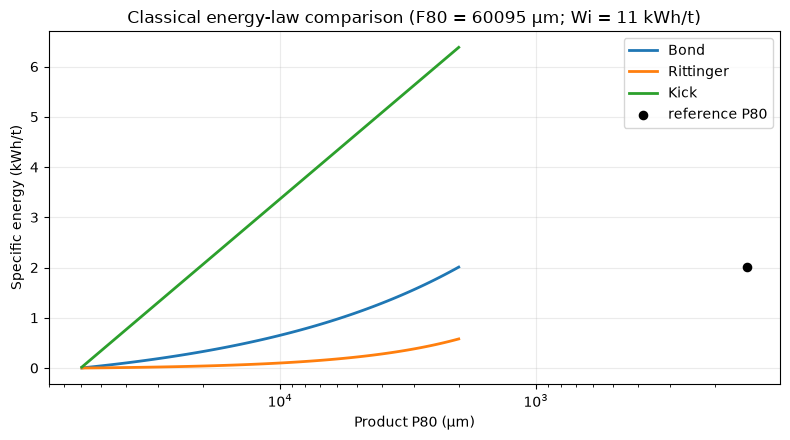

In [4]:
# Paso ejecutable del método OreFlow explicado en la celda anterior.
fig, ax = plt.subplots(figsize=(8, 4.5))
for name in ('bond', 'rittinger', 'kick'):
    ax.plot(curves['p80_um'], curves[name], label=name.title(), linewidth=2)
ax.scatter([150], [curves['bond'][int(np.argmin(abs(np.asarray(curves['p80_um']) - 150))) ]], s=35, color='black', zorder=3, label='reference P80')
ax.set_xscale('log'); ax.invert_xaxis(); ax.set(xlabel='Product P80 (µm)', ylabel='Specific energy (kWh/t)', title=f'Classical energy-law comparison (F80 = {f80:.0f} µm; Wi = {wi:g} kWh/t)')
ax.grid(True, alpha=.25); ax.legend(); fig.tight_layout()

Cuantifica la dispersión en la reducción real del caso. Interprétala como desacuerdo estructural entre hipótesis, no como intervalo de confianza ni error observado en planta.

In [5]:
# Paso ejecutable del método OreFlow explicado en la celda anterior.
actual_p80 = float(metrics['p80_um'])
point = law_curves(wi, f80, np.array([actual_p80]))
comparison = pd.DataFrame({'law': ['Bond', 'Rittinger', 'Kick'],
                           'energy_kwh_t': [point['bond'][0], point['rittinger'][0], point['kick'][0]]})
comparison['relative_to_bond'] = comparison.energy_kwh_t / comparison.energy_kwh_t.iloc[0]
display(comparison)

,law,energy_kwh_t,relative_to_bond
0,Bond,8.532744,1.000000
1,Rittinger,7.981513,0.935398
2,Kick,11.246972,1.318095


## Resultados

Las curvas coinciden por construcción en la reducción de referencia; fuera de ella, su separación refleja formas funcionales distintas. OreFlow usa Bond para la energía estándar reportada y no suma las alternativas. La comparación no tiene residuo de energía medido en planta y no permite elegir la mejor ley para una planta específica.

## Resumen

La comparación controlada en el mismo caso hace visible la selección del modelo: calibrar hace coincidir las leyes en un punto, no en todos. Siguen aplicando la calificación de finura de Bond y su base energética.

## Referencias

- https://www.globalminingguidelines.org/guidelines/bond-efficiency/
- https://doi.org/10.1016/0301-7516(80)90034-4
- https://doi.org/10.1016/0301-7516(80)90034-4